In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error

In [10]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [11]:
df = pd.read_csv("train.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset Shape: (80000, 40)

Columns:
['patient_id', 'site_id', 'triage_nurse_id', 'arrival_mode', 'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season', 'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'disposition', 'ed_los_hours', 'triage_acuity']


,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,gcs_total,pain_score,weight_kg,height_cm,bmi,shock_index,news2_score,disposition,ed_los_hours,triage_acuity
0,TG-UXRGA9UCO,SITE-TMP-01,NURSE-0033,walk-in,6,Monday,5,spring,morning,43,...,14,7,52.3,165.4,19.1,0.725,8,discharged,7.35,2
1,TG-B19DBBS2G,SITE-HEL-01,NURSE-0001,walk-in,6,Thursday,4,spring,morning,72,...,15,-1,73.3,164.4,27.1,0.739,1,discharged,0.70,5
2,TG-GZ97W7M6V,SITE-HEL-02,NURSE-0005,walk-in,8,Saturday,4,spring,morning,82,...,15,3,77.1,183.7,22.8,0.798,2,discharged,0.63,5
3,TG-THIB2TN9Q,SITE-HEL-02,NURSE-0026,police,7,Sunday,3,spring,morning,50,...,15,7,49.6,172.6,16.6,0.812,2,discharged,1.99,3
4,TG-J3U3LQ2QY,SITE-HEL-02,NURSE-0044,walk-in,5,Tuesday,5,spring,night,62,...,15,4,71.9,173.4,23.9,0.812,2,transferred,3.58,3


In [12]:
features = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "heart_rate",
    "respiratory_rate",
    "temperature_c",
    "spo2",
    "pain_score"
]

df = df[features + ["triage_acuity"]]

print("Selected Features:")
print(features)

df.head()

Selected Features:
['age', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'pain_score']


,age,systolic_bp,diastolic_bp,heart_rate,respiratory_rate,temperature_c,spo2,pain_score,triage_acuity
0,43,79.0,57.5,57.3,17.9,37.0,92.1,7,2
1,72,131.7,93.4,97.3,17.2,36.9,99.4,-1,5
2,82,94.7,83.3,75.6,14.7,37.3,100.0,3,5
3,50,134.2,51.8,109.0,17.6,38.2,96.0,7,3
4,62,140.1,75.4,113.7,17.6,36.6,99.1,4,3


In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age                    0
systolic_bp         4146
diastolic_bp        4146
heart_rate             0
respiratory_rate    3067
temperature_c        574
spo2                   0
pain_score             0
triage_acuity          0
dtype: int64


In [14]:
df[features] = df[features].fillna(df[features].median())

print("Missing values after preprocessing:")
print(df.isnull().sum())

Missing values after preprocessing:
age                 0
systolic_bp         0
diastolic_bp        0
heart_rate          0
respiratory_rate    0
temperature_c       0
spo2                0
pain_score          0
triage_acuity       0
dtype: int64


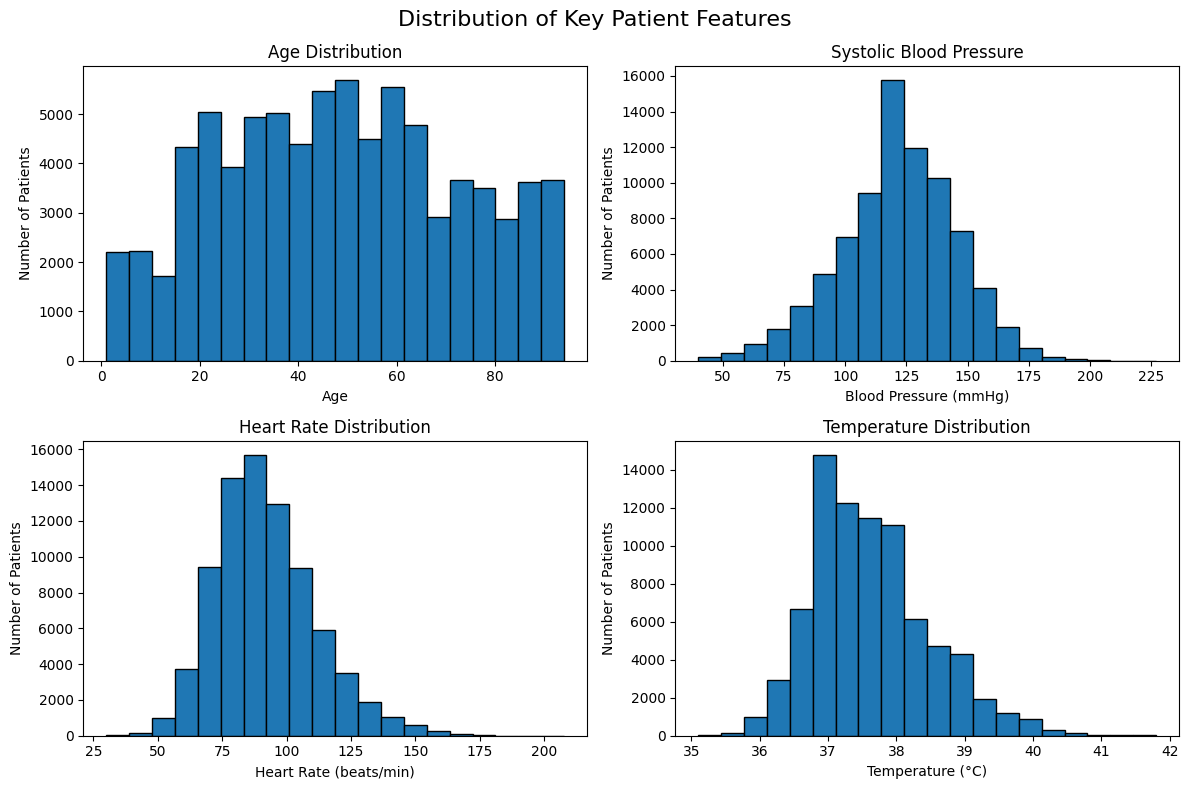

In [15]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.hist(df["age"], bins=20, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.subplot(2, 2, 2)
plt.hist(df["systolic_bp"], bins=20, edgecolor="black")
plt.title("Systolic Blood Pressure")
plt.xlabel("Blood Pressure (mmHg)")
plt.ylabel("Number of Patients")

plt.subplot(2, 2, 3)
plt.hist(df["heart_rate"], bins=20, edgecolor="black")
plt.title("Heart Rate Distribution")
plt.xlabel("Heart Rate (beats/min)")
plt.ylabel("Number of Patients")

plt.subplot(2, 2, 4)
plt.hist(df["temperature_c"], bins=20, edgecolor="black")
plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of Patients")

plt.suptitle("Distribution of Key Patient Features", fontsize=16)

plt.tight_layout()
plt.show()

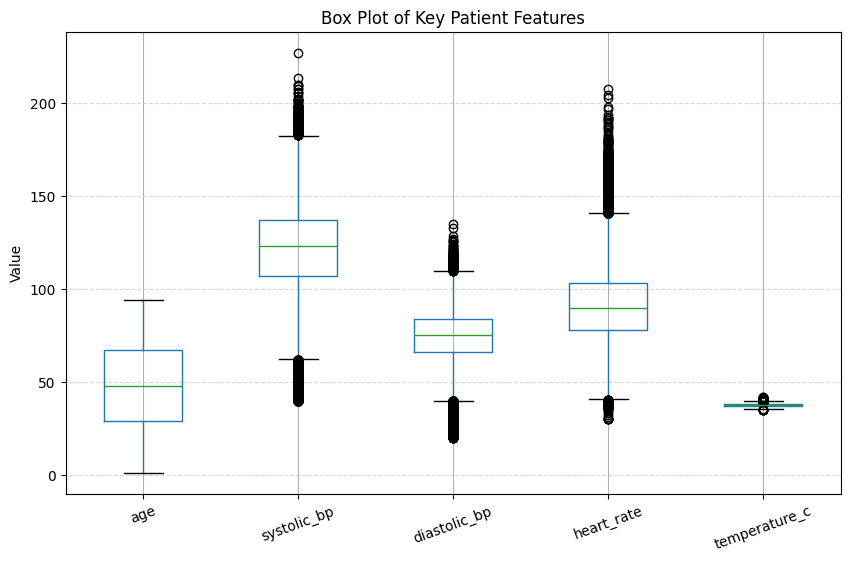

In [16]:
plt.figure(figsize=(10, 6))

df[
    [
        "age",
        "systolic_bp",
        "diastolic_bp",
        "heart_rate",
        "temperature_c"
    ]
].boxplot()

plt.title("Box Plot of Key Patient Features")
plt.ylabel("Value")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [17]:
X = df[features]
y = df["triage_acuity"]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (80000, 8)
Target Shape: (80000,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data: (64000, 8)
Testing Data : (16000, 8)


In [19]:
triage_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

triage_model.fit(X_train, y_train)

print("Random Forest Triage Model Trained Successfully.")

Random Forest Triage Model Trained Successfully.


In [20]:
y_pred = triage_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Triage Accuracy:", round(accuracy * 100, 2), "%")


Triage Accuracy: 78.99 %


In [21]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           1       0.84      0.63      0.72       644
           2       0.86      0.89      0.87      2688
           3       0.85      0.83      0.84      5784
           4       0.71      0.73      0.72      4604
           5       0.72      0.74      0.73      2280

    accuracy                           0.79     16000
   macro avg       0.79      0.76      0.78     16000
weighted avg       0.79      0.79      0.79     16000



In [23]:
np.random.seed(42)

waiting_time_map = {
    1: 5,
    2: 15,
    3: 30,
    4: 50,
    5: 70
}

df["waiting_time"] = (
    df["triage_acuity"].map(waiting_time_map)
    + np.random.randint(-5, 6, size=len(df))
)

print(df[["triage_acuity", "waiting_time"]].head())

   triage_acuity  waiting_time
0              2            16
1              5            68
2              5            75
3              3            32
4              3            29


In [24]:
X_wait = df[features]
y_wait = df["waiting_time"]

X_train, X_test, y_train, y_test = train_test_split(
    X_wait, y_wait, test_size=0.2, random_state=42
)

wait_model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

wait_model.fit(X_train, y_train)

print("Waiting-time model trained successfully.")

Waiting-time model trained successfully.


In [25]:
pred = wait_model.predict(X_test)

mae = mean_absolute_error(y_test, pred)

print("Mean Absolute Error:",
      round(mae, 2), "minutes")

Mean Absolute Error: 6.36 minutes


In [26]:
patient = pd.DataFrame([{
    "age": 45,
    "systolic_bp": 130,
    "diastolic_bp": 82,
    "heart_rate": 95,
    "respiratory_rate": 20,
    "temperature_c": 37.2,
    "spo2": 97,
    "pain_score": 5
}])

triage = triage_model.predict(patient)[0]
waiting = wait_model.predict(patient)[0]

levels = {
    1: "Critical / Immediate",
    2: "Emergent",
    3: "Urgent",
    4: "Less Urgent",
    5: "Non-Urgent"
}

print("=" * 40)
print("   SMART HOSPITAL PREDICTION")
print("=" * 40)
print("Triage Level :", triage)
print("Priority     :", levels[triage])
print("Waiting Time :", round(waiting), "minutes")
print("=" * 40)

   SMART HOSPITAL PREDICTION
Triage Level : 3
Priority     : Urgent
Waiting Time : 41 minutes
